In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
df = pd.read_csv("loan_approval_dataset.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (4269, 13)


,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,1,2,Graduate,No,9600000,29900000,12,778,2400000,17600000,22700000,8000000,Approved
1,2,0,Not Graduate,Yes,4100000,12200000,8,417,2700000,2200000,8800000,3300000,Rejected
2,3,3,Graduate,No,9100000,29700000,20,506,7100000,4500000,33300000,12800000,Rejected
3,4,3,Graduate,No,8200000,30700000,8,467,18200000,3300000,23300000,7900000,Rejected
4,5,5,Not Graduate,Yes,9800000,24200000,20,382,12400000,8200000,29400000,5000000,Rejected


In [3]:
print("Dataset Information:")
df.info()

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Shape:")
print(df.shape)

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 4269 entries, 0 to 4268
Data columns (total 13 columns):
 #   Column                     Non-Null Count  Dtype
---  ------                     --------------  -----
 0   loan_id                    4269 non-null   int64
 1    no_of_dependents          4269 non-null   int64
 2    education                 4269 non-null   str  
 3    self_employed             4269 non-null   str  
 4    income_annum              4269 non-null   int64
 5    loan_amount               4269 non-null   int64
 6    loan_term                 4269 non-null   int64
 7    cibil_score               4269 non-null   int64
 8    residential_assets_value  4269 non-null   int64
 9    commercial_assets_value   4269 non-null   int64
 10   luxury_assets_value       4269 non-null   int64
 11   bank_asset_value          4269 non-null   int64
 12   loan_status               4269 non-null   str  
dtypes: int64(10), str(3)
memory usage: 433.7 KB

Column Names:
['loan_id

In [4]:
print("Missing values in each column:")
print(df.isnull().sum())

print("\nTotal missing values:", df.isnull().sum().sum())

Missing values in each column:
loan_id                      0
 no_of_dependents            0
 education                   0
 self_employed               0
 income_annum                0
 loan_amount                 0
 loan_term                   0
 cibil_score                 0
 residential_assets_value    0
 commercial_assets_value     0
 luxury_assets_value         0
 bank_asset_value            0
 loan_status                 0
dtype: int64

Total missing values: 0


In [5]:
print("Total duplicate rows:", df.duplicated().sum())

Total duplicate rows: 0


In [6]:
df.columns = df.columns.str.strip()

df.drop('loan_id', axis=1, inplace=True)

print("Updated dataset shape:", df.shape)
display(df.head())

Updated dataset shape: (4269, 12)


,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,2,Graduate,No,9600000,29900000,12,778,2400000,17600000,22700000,8000000,Approved
1,0,Not Graduate,Yes,4100000,12200000,8,417,2700000,2200000,8800000,3300000,Rejected
2,3,Graduate,No,9100000,29700000,20,506,7100000,4500000,33300000,12800000,Rejected
3,3,Graduate,No,8200000,30700000,8,467,18200000,3300000,23300000,7900000,Rejected
4,5,Not Graduate,Yes,9800000,24200000,20,382,12400000,8200000,29400000,5000000,Rejected


In [7]:
cat_col = ['education', 'self_employed', 'loan_status']

for col in cat_col:
    df[col] = df[col].str.strip()

print("Categorical values cleaned successfully!")

for col in cat_col:
    print(f"\n{col}:")
    print(df[col].unique())

Categorical values cleaned successfully!

education:
<StringArray>
['Graduate', 'Not Graduate']
Length: 2, dtype: str

self_employed:
<StringArray>
['No', 'Yes']
Length: 2, dtype: str

loan_status:
<StringArray>
['Approved', 'Rejected']
Length: 2, dtype: str


In [8]:
df['education'] = df['education'].map({
    'Not Graduate': 0,
    'Graduate': 1
})

df['self_employed'] = df['self_employed'].map({
    'No': 0,
    'Yes': 1
})

df['loan_status'] = df['loan_status'].map({
    'Rejected': 0,
    'Approved': 1
})

display(df.head())

,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,2,1,0,9600000,29900000,12,778,2400000,17600000,22700000,8000000,1
1,0,0,1,4100000,12200000,8,417,2700000,2200000,8800000,3300000,0
2,3,1,0,9100000,29700000,20,506,7100000,4500000,33300000,12800000,0
3,3,1,0,8200000,30700000,8,467,18200000,3300000,23300000,7900000,0
4,5,0,1,9800000,24200000,20,382,12400000,8200000,29400000,5000000,0


In [9]:
print(df.isnull().sum())

no_of_dependents            0
education                   0
self_employed               0
income_annum                0
loan_amount                 0
loan_term                   0
cibil_score                 0
residential_assets_value    0
commercial_assets_value     0
luxury_assets_value         0
bank_asset_value            0
loan_status                 0
dtype: int64


In [10]:
X = df.drop('loan_status', axis=1)
y = df['loan_status']

print("Features shape:", X.shape)
print("Target shape:", y.shape)

display(X.head())
display(y.head())

Features shape: (4269, 11)
Target shape: (4269,)


,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value
0,2,1,0,9600000,29900000,12,778,2400000,17600000,22700000,8000000
1,0,0,1,4100000,12200000,8,417,2700000,2200000,8800000,3300000
2,3,1,0,9100000,29700000,20,506,7100000,4500000,33300000,12800000
3,3,1,0,8200000,30700000,8,467,18200000,3300000,23300000,7900000
4,5,0,1,9800000,24200000,20,382,12400000,8200000,29400000,5000000


0    1
1    0
2    0
3    0
4    0
Name: loan_status, dtype: int64

In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training features: (3415, 11)
Testing features: (854, 11)

Training target distribution:
loan_status
1    2125
0    1290
Name: count, dtype: int64

Testing target distribution:
loan_status
1    531
0    323
Name: count, dtype: int64


In [12]:
nb_model = GaussianNB()

nb_model.fit(X_train, y_train)

print("Naive Bayes model trained successfully!")

Naive Bayes model trained successfully!


In [13]:
y_pred_nb = nb_model.predict(X_test)

print("Actual values:")
print(y_test.head(10).tolist())

print("\nPredicted values:")
print(y_pred_nb[:10])

Actual values:
[0, 0, 0, 1, 1, 1, 1, 0, 1, 0]

Predicted values:
[1 0 1 1 1 1 1 1 1 0]


In [14]:
print("Naive Bayes Performance")

print("Accuracy:", accuracy_score(y_test, y_pred_nb))
print("Precision:", precision_score(y_test, y_pred_nb))
print("Recall:", recall_score(y_test, y_pred_nb))
print("F1 Score:", f1_score(y_test, y_pred_nb))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_nb,
    target_names=['Rejected', 'Approved']
))

Naive Bayes Performance
Accuracy: 0.752927400468384
Precision: 0.721606648199446
Recall: 0.9811676082862524
F1 Score: 0.8316041500399042

Classification Report:
              precision    recall  f1-score   support

    Rejected       0.92      0.38      0.54       323
    Approved       0.72      0.98      0.83       531

    accuracy                           0.75       854
   macro avg       0.82      0.68      0.68       854
weighted avg       0.80      0.75      0.72       854



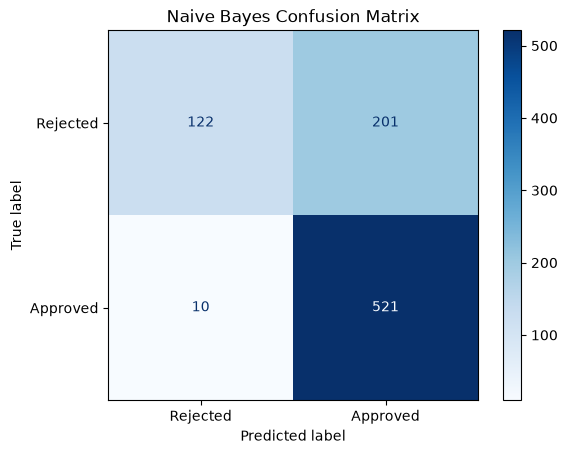

In [15]:
cm_nb = confusion_matrix(y_test, y_pred_nb)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_nb,
    display_labels=['Rejected', 'Approved']
)

disp.plot(cmap='Blues')
plt.title("Naive Bayes Confusion Matrix")
plt.show()

In [16]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed!")

print("Training shape:", X_train_scaled.shape)
print("Testing shape:", X_test_scaled.shape)

Feature scaling completed!
Training shape: (3415, 11)
Testing shape: (854, 11)


In [17]:
knn_model = KNeighborsClassifier(n_neighbors=5)

knn_model.fit(X_train_scaled, y_train)

print("KNN model trained successfully!")

KNN model trained successfully!


In [18]:
y_pred_knn = knn_model.predict(X_test_scaled)

print("Actual values:")
print(y_test.head(10).tolist())

print("\nPredicted values:")
print(y_pred_knn[:10])

Actual values:
[0, 0, 0, 1, 1, 1, 1, 0, 1, 0]

Predicted values:
[1 0 0 1 1 1 1 1 1 0]


In [19]:
print("KNN Performance")

print("Accuracy:", accuracy_score(y_test, y_pred_knn))
print("Precision:", precision_score(y_test, y_pred_knn))
print("Recall:", recall_score(y_test, y_pred_knn))
print("F1 Score:", f1_score(y_test, y_pred_knn))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_knn,
    target_names=['Rejected', 'Approved']
))

KNN Performance
Accuracy: 0.8946135831381733
Precision: 0.9060773480662984
Recall: 0.9265536723163842
F1 Score: 0.9162011173184358

Classification Report:
              precision    recall  f1-score   support

    Rejected       0.87      0.84      0.86       323
    Approved       0.91      0.93      0.92       531

    accuracy                           0.89       854
   macro avg       0.89      0.88      0.89       854
weighted avg       0.89      0.89      0.89       854



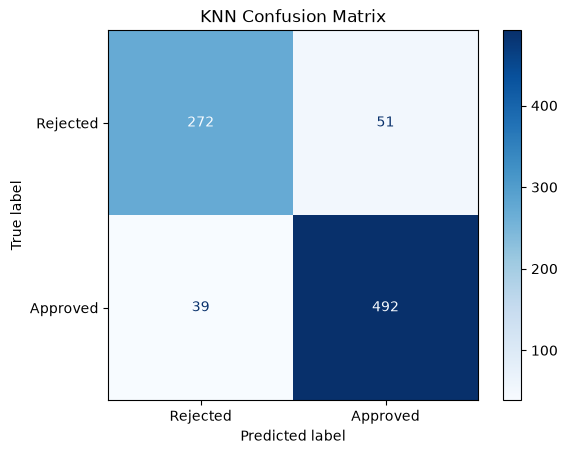

In [20]:
cm_knn = confusion_matrix(y_test, y_pred_knn)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_knn,
    display_labels=['Rejected', 'Approved']
)

disp.plot(cmap='Blues')
plt.title("KNN Confusion Matrix")
plt.show()

In [21]:
comparison = pd.DataFrame({
    'Model': ['Naive Bayes', 'KNN'],

    'Accuracy': [
        accuracy_score(y_test, y_pred_nb),
        accuracy_score(y_test, y_pred_knn)
    ],

    'Precision': [
        precision_score(y_test, y_pred_nb),
        precision_score(y_test, y_pred_knn)
    ],

    'Recall': [
        recall_score(y_test, y_pred_nb),
        recall_score(y_test, y_pred_knn)
    ],

    'F1 Score': [
        f1_score(y_test, y_pred_nb),
        f1_score(y_test, y_pred_knn)
    ]
})

display(comparison.round(4))

,Model,Accuracy,Precision,Recall,F1 Score
0,Naive Bayes,0.7529,0.7216,0.9812,0.8316
1,KNN,0.8946,0.9061,0.9266,0.9162
